rumz
# Notebook for processing layers in ice
### March 25
#### V. 1.1.2
- Updated to match spectralBubbles V. 1.1.2

This notebook processes hyperspectral images of ice and extracts information in regards to climate proxies.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run

In [1]:
import warnings
import sys
import os

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from icespec import savePNG
from icespec import ageConversion

### Users should fill in variables with desired core info
Use HSI_July2024 Spreadsheet for ID and section names

Debug variable prints more information during processing

In [2]:
datasetPath = '/data/icecores/HSI_2024.csv' #path to csv file on computer or server

outputDir = '/data/icecores/Output' #png output path

DataID = "HSIUM-198" #insert DataID from excel file inside quotation marks

## GISP2-2404: HSIUM-167-170
## SPC14-1317: HSIUM-NA
## WDC06A- 2765: HSIUM-196-198

Debug = False

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims = processice.getDataPath(datasetPath, DataID, outputDir)

outputPath = f"{save_path}/"
print("Output Path: ", outputPath)

%matplotlib ipympl
data_nparr, w_ref, d_ref, fwhm = processice.getEnviData(dataPath)

Core:  WDC06A
Section:  2765
Lighting: Top light - 100%, Bottom Light - 0%
Exposure:  16
Top Depth:  2764.0
Bottom Depth:  2764.2
Length =  0.1999999999998181
Dimensions:  1240, 2400, 100, 730
Output Path:  /data/icecores/Output/AN/WDC/WDC06A/WDC06A-2765/


In [4]:
segment_boundaries, cm_per_pixel = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, end_px=px_dims[1])
print("cm per px: ", cm_per_pixel)

#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
dataSize = 	px_dims
stdSize = [530, 820, 200, 900] #standard sizing

cm per px:  60.00000000005457


The new dimensions will be: 530x1160
Trimmed shapes: (1160, 530, 224), W_ref: (256, 530, 224), D_ref: (100, 530, 224)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


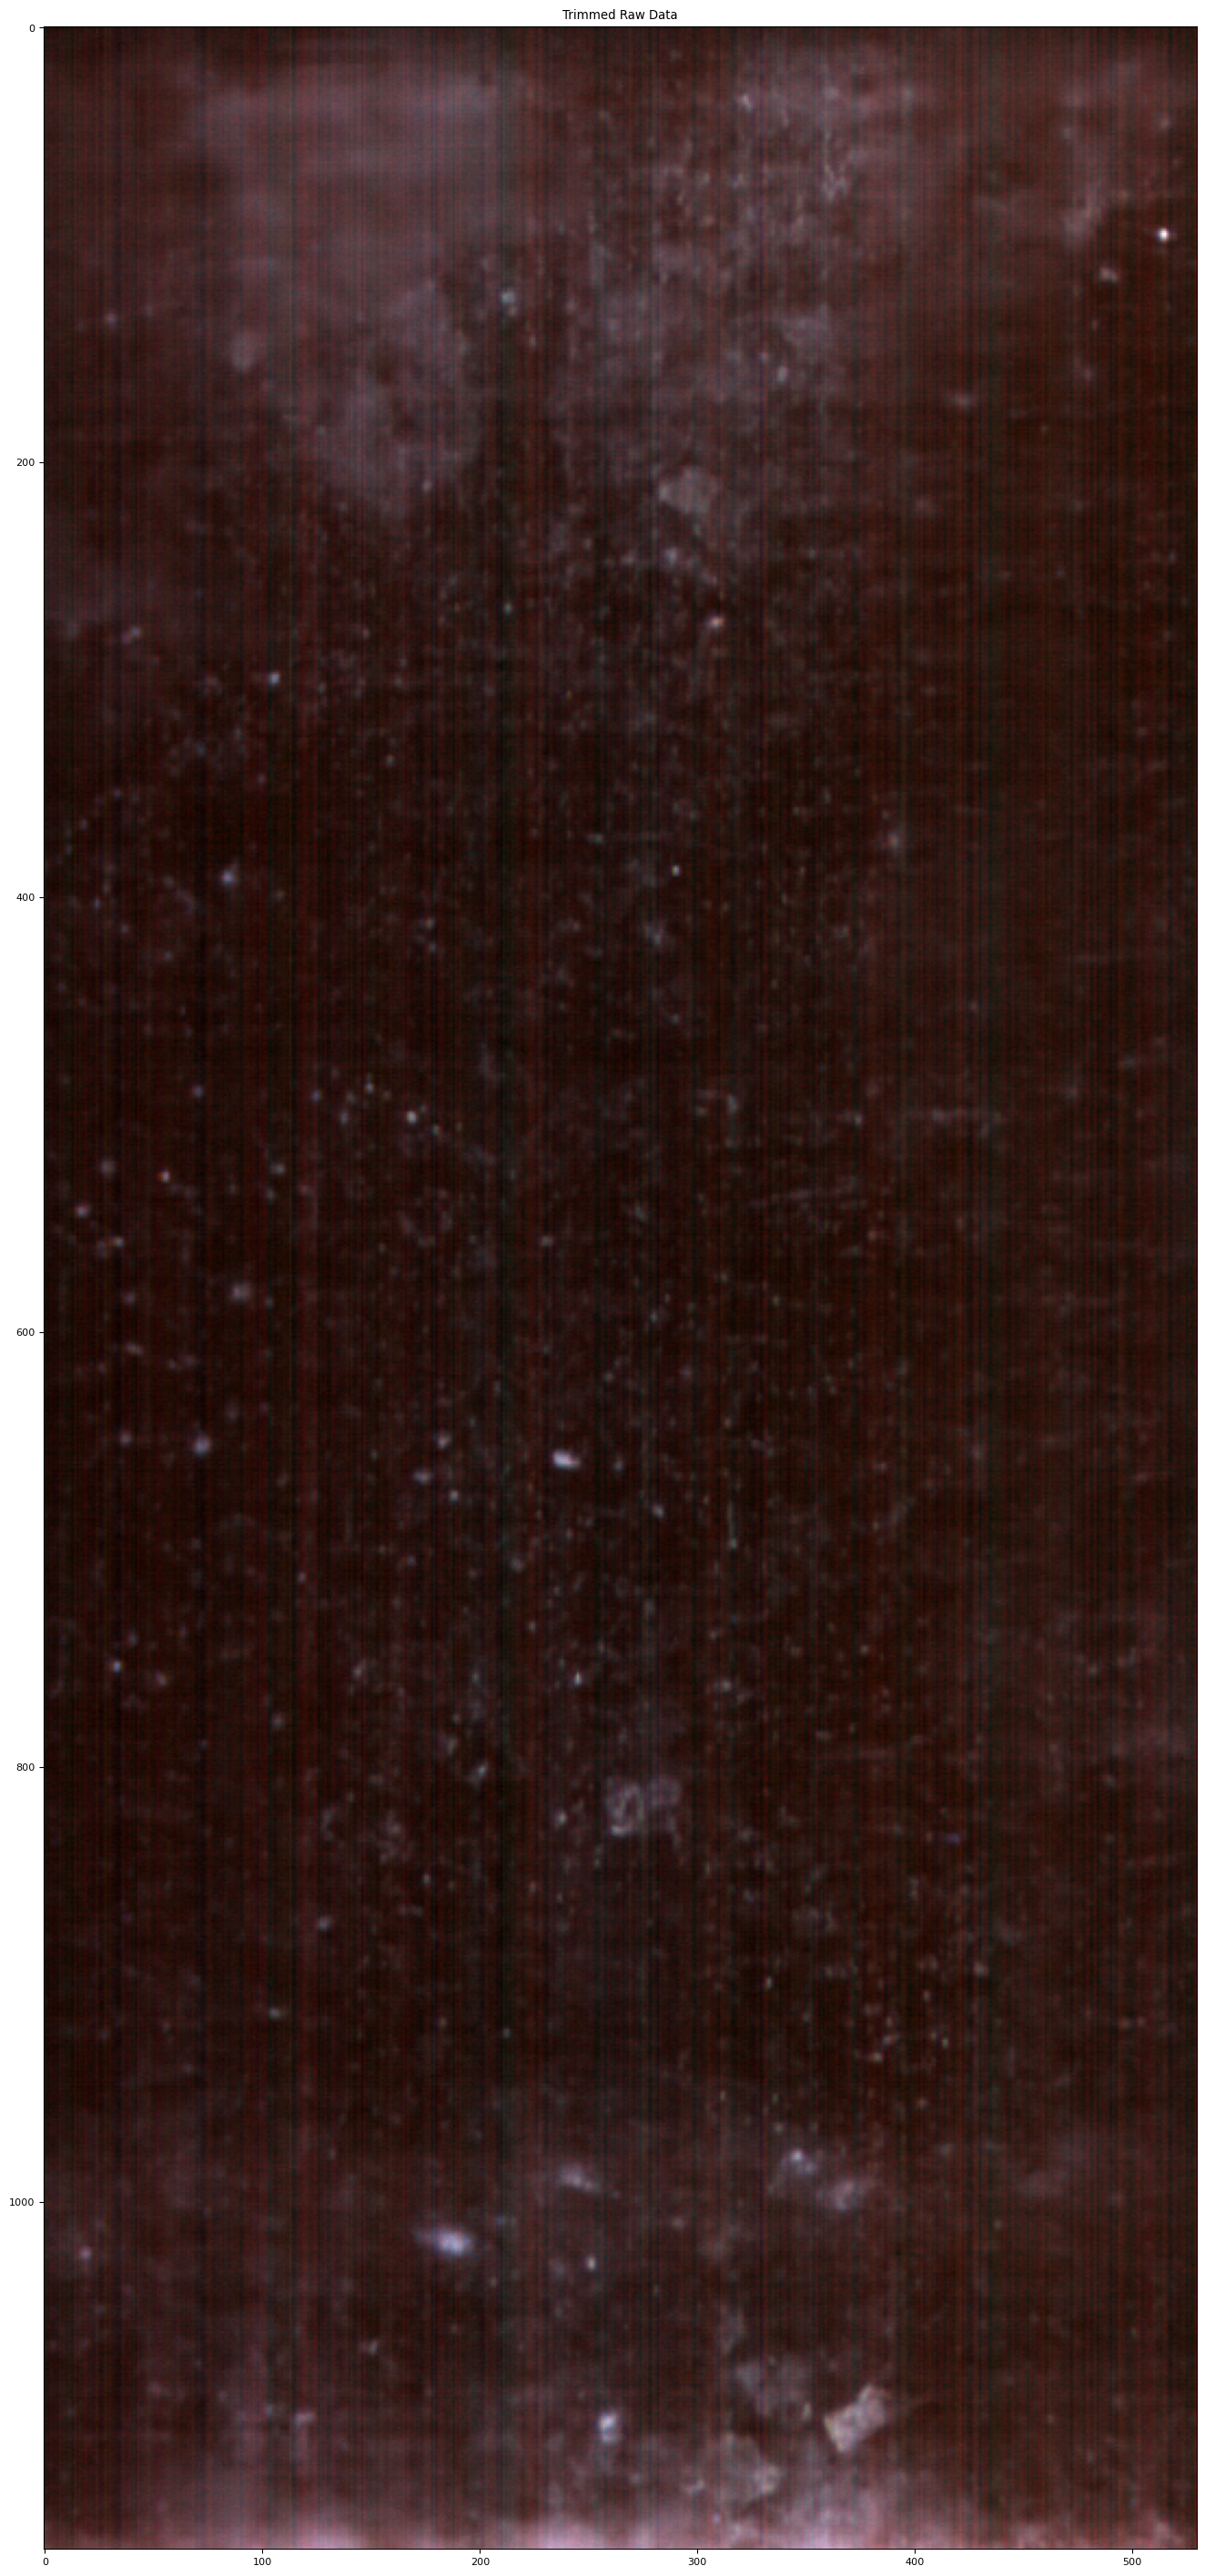

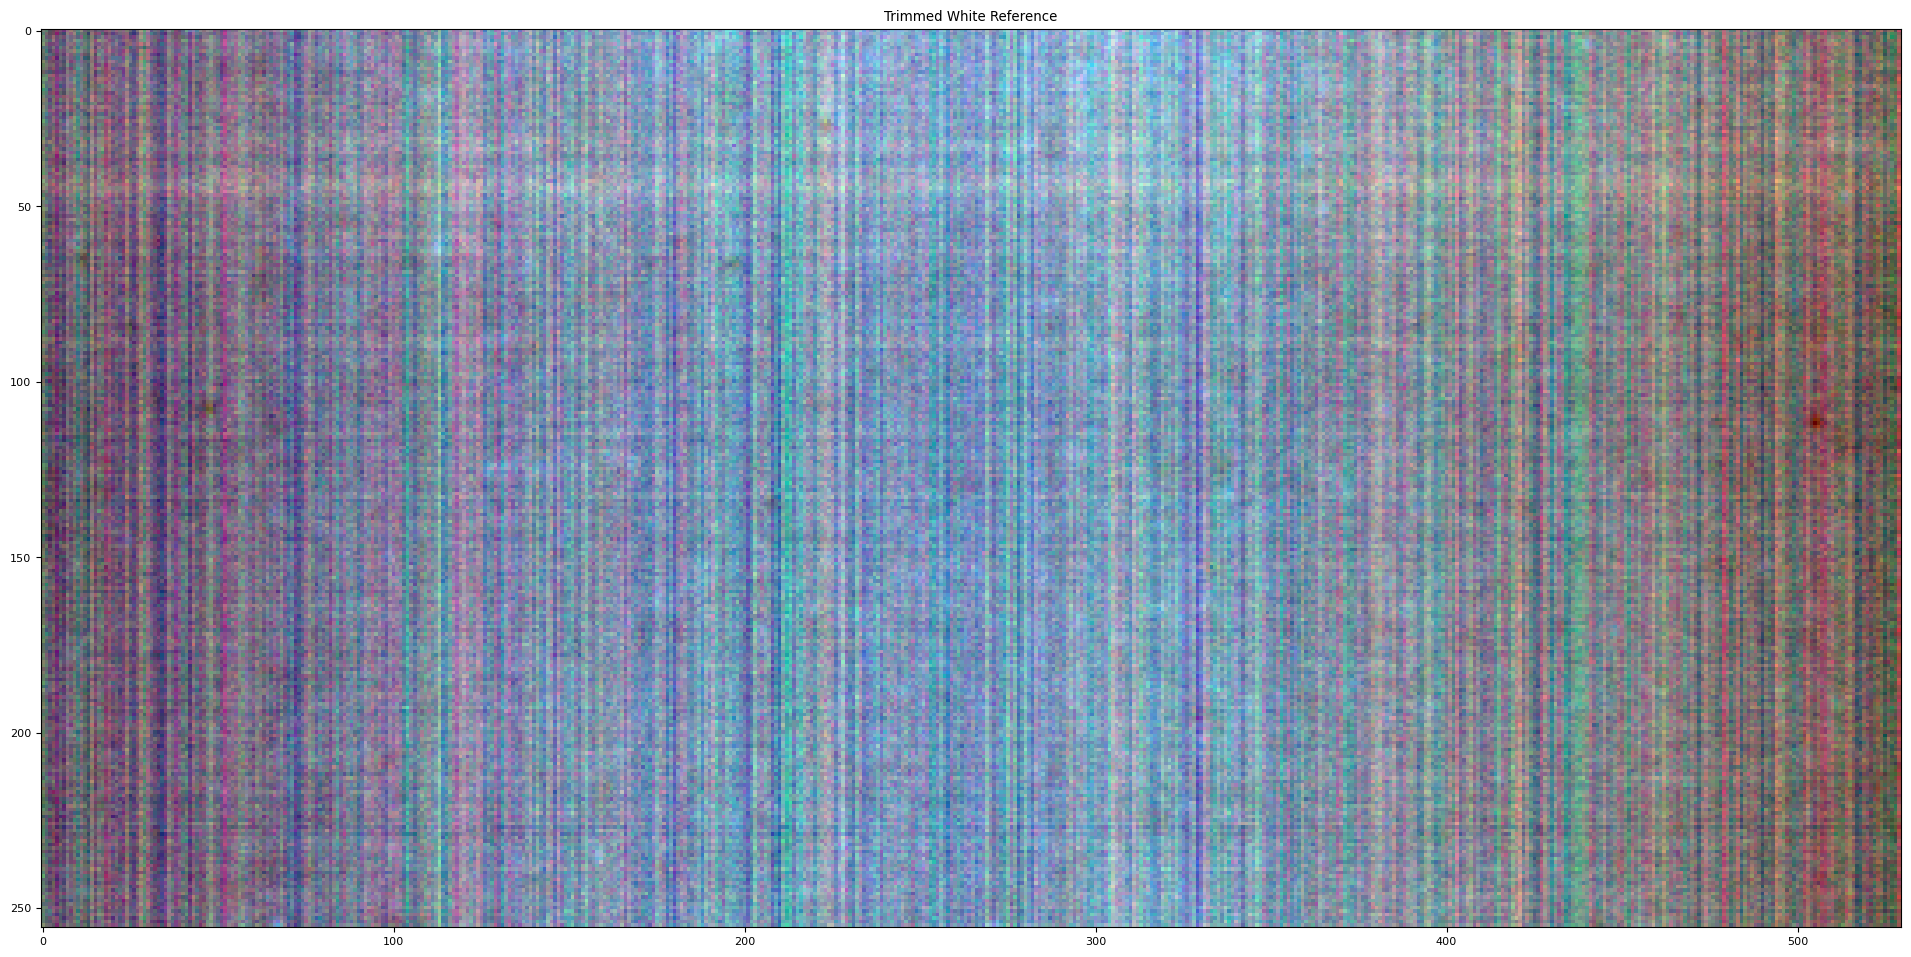

In [5]:
%matplotlib inline
trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug=True) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)
#filtered_img = processice.remove_bands(correctedData, trimmedData[1])


inpainted_img = processice.bubbles(correctedData,  fwhm)

sum_img = processice.channel_sums(inpainted_img)

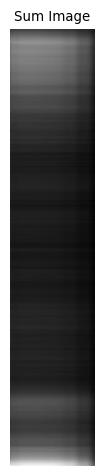

In [6]:
import matplotlib.pyplot as plt

plt.imshow(sum_img, cmap='gray')
plt.axis('off')
plt.title("Sum Image")
plt.tight_layout()
plt.savefig(f"{outputPath}sumImg_198.png", dpi=300, bbox_inches='tight')
plt.show()

In [7]:
start_cm = int(top_depth * 100)
depths_cm = np.arange(start_cm, start_cm + len(segment_boundaries))
depth_col = "Depth"
age_col = "Ice Age"
header = 40
# age_df = ageConversion.map_depths_to_ages("/data/icecores/ICD/WDC06A/WD2014_26Aug2014.xlsx", depths_cm, top_depth, depth_col, age_col, header)
# print(age_df)